# PANSS model with a fixed matrix-element subset + Ridge regression

Companion to `clinical_scores_model.ipynb`. This version:

1. Uses **every individual matrix element** (region-pair / edge) of the GEC or Ftau connectivity matrix as a candidate feature — not aggregated row/col stats.
2. Correlates each matrix element with PANSS **across all subjects** and keeps the ones whose `|corr| > threshold`. This selection is fixed once, across all subjects — deliberately, so that a brand-new subject with no PANSS score yet can be reduced to the same fixed feature set and scored by the fitted model.
3. Fits a `RidgeCV` regressor (L2-regularized, so it tolerates a feature count comparable to or exceeding the subject count) on the selected matrix elements, evaluated with LOOCV across subjects.

Two independent variants are built, each using only one feature type:
- **Ftau-only**: lag-τ (tau=1) functional connectivity matrix
- **GEC-only**: effective connectivity matrix (from `study_results`)

Because feature selection uses the full sample, the LOOCV numbers below are optimistic/leaky by design (same tradeoff as the original region-elimination notebook) — the point of this design is a fixed, known-in-advance feature subset, not a leakage-free estimate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from scipy.stats import pearsonr
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Load data (same `data/` pickles as `clinical_scores_model.ipynb`)

In [2]:
# GEC (per-subject effective connectivity)
study_results = np.load("./data/study_results.pkl", allow_pickle=True)

# fmri timeseries
fmri = np.load('./data/HCP_early_psychosis_timeseries_cleaned.npz')
ts_ap = fmri['ts_ap']
ts_nap = fmri['ts_nap']

# clinical scores
clinical = np.load('./data/HCP_early_psychosis_clinical_scores.npz')
panss_AP = clinical["panss_AP"]
panss_NAP = clinical["panss_NAP"]

# Perturbability maps: per-region (100,) scores per subject, keyed by group then subject index
p2h_maps = np.load("./data/p2h_maps.pkl", allow_pickle=True)
p2o_maps = np.load("./data/p2o_maps.pkl", allow_pickle=True)

## Shared feature-extraction helpers

In [3]:
def compute_ftau_matrix(sub_ts, tau=1):
    """Lag-tau (empirical) functional connectivity matrix."""
    n_regions = sub_ts.shape[0]
    ts_t0 = sub_ts[:, :-tau]
    ts_ttau = sub_ts[:, tau:]
    full_corr = np.corrcoef(ts_t0, ts_ttau)
    return full_corr[:n_regions, n_regions:]


def offdiag_mask(n):
    """Boolean mask selecting every off-diagonal position of an n x n matrix."""
    return ~np.eye(n, dtype=bool)


def flatten_offdiag_features(matrix):
    """
    Every off-diagonal element of the (possibly asymmetric) connectivity
    matrix, flattened to one feature vector. Ordering is consistent across
    subjects (same matrix shape), so column j always refers to the same
    region-pair for every subject.
    """
    mat = np.nan_to_num(matrix)
    return mat[offdiag_mask(mat.shape[0])]

## Build per-subject matrices (Ftau or GEC), pooled across AP/NAP

In [4]:
FEATURE_MATRIX_BUILDERS = {
    "Ftau": lambda idx, group, ts_array: compute_ftau_matrix(ts_array[idx, :, :], tau=1),
    "GEC": lambda idx, group, ts_array: study_results[group][idx]["GEC_matrix"],
}


def build_dataset_elements(feature_type, include_perturbability=False):
    """
    Assemble X, y for one feature type: every off-diagonal matrix element
    as a feature, pooling AP (group_flag=0) and NAP (group_flag=1).
    If include_perturbability, each subject's p2h and p2o per-region
    (100,) scores are appended onto the matrix-element features.
    """
    matrix_builder = FEATURE_MATRIX_BUILDERS[feature_type]
    X_list, y_list = [], []

    for group, ts_array, panss in (("AP", ts_ap, panss_AP), ("NAP", ts_nap, panss_NAP)):
        n_subjects = ts_array.shape[0]
        for idx in range(n_subjects):
            matrix = matrix_builder(idx, group, ts_array)
            feats = flatten_offdiag_features(matrix)
            if include_perturbability:
                feats = np.concatenate([feats, p2h_maps[group][idx], p2o_maps[group][idx]])
            group_flag = 0 if group == "AP" else 1
            X_list.append(np.append(feats, group_flag))
            y_list.append(panss[idx])

    X = np.array(X_list)
    y = np.array(y_list)

    valid_mask = ~np.isnan(y)
    return X[valid_mask], y[valid_mask]

## Fixed feature selection (full sample) + Ridge LOOCV

1. Correlate every matrix element (column of `X`) with PANSS **across all subjects** and keep the ones whose `|corr| > threshold`. This is computed once, on the full dataset — the resulting index set is fixed and identical for every subject, current or new.
2. Fit `RidgeCV` (L2-regularized) on just those selected columns, evaluated with LOOCV: refit per fold on the training subjects, predict the held-out subject.

Because step 1 uses every subject (including whichever one LOOCV later holds out), this is leaky by design — the tradeoff is a feature subset that's genuinely fixed in advance, so a new subject with no PANSS score yet can be reduced to the same columns and scored.

In [5]:
def select_fixed_features(X, y, threshold):
    """
    Full-sample correlation-threshold feature selection: correlate every
    column of X with y using every subject, and fix the set of indices
    whose |corr| clears threshold. Deliberately leaky (uses all subjects)
    so the resulting index set is a single fixed subset usable for any
    subject, including a brand-new one with no PANSS score yet.
    """
    corrs = np.array([pearsonr(X[:, j], y)[0] for j in range(X.shape[1])])
    corrs = np.nan_to_num(corrs)
    selected = np.where(np.abs(corrs) > threshold)[0]

    if selected.size == 0:
        selected = np.array([np.argmax(np.abs(corrs))])

    return selected


def run_ridge_loocv(X, y):
    """
    RidgeCV regression evaluated by LOOCV: refit (including internal alpha
    selection) per fold on the training subjects, predict the held-out
    subject. X's columns are assumed already fixed by select_fixed_features.
    """
    loo = LeaveOneOut()
    y_true_all, y_pred_all = [], []

    for train_index, test_index in loo.split(X):
        model = RidgeCV(alphas=np.logspace(-3, 3, 13))
        model.fit(X[train_index], y[train_index])
        pred = model.predict(X[test_index])

        y_true_all.append(y[test_index][0])
        y_pred_all.append(pred[0])

    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)
    corr, pval = pearsonr(y_true_all, y_pred_all)

    return {
        "y_true": y_true_all,
        "y_pred": y_pred_all,
        "rmse": np.sqrt(mean_squared_error(y_true_all, y_pred_all)),
        "mae": mean_absolute_error(y_true_all, y_pred_all),
        "r2": r2_score(y_true_all, y_pred_all),
        "corr": corr,
        "pval": pval,
    }

## Reporting helper (build features, fix the subset, run LOOCV, plot)

In [6]:
def report_fixed_feature_model(feature_type, threshold, n_regions=100):
    X, y = build_dataset_elements(feature_type)
    X = X[:, :-1]  # drop the group flag - it's categorical, not a connectivity feature

    selected_idx = select_fixed_features(X, y, threshold)
    all_rows, all_cols = np.where(offdiag_mask(n_regions))
    selected_pairs = list(zip(all_rows[selected_idx].tolist(), all_cols[selected_idx].tolist()))

    X_sel = X[:, selected_idx]
    loocv = run_ridge_loocv(X_sel, y)
    final_model = RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(X_sel, y)

    print(f"\n=== {feature_type}: fixed matrix-element subset + Ridge (threshold={threshold}) ===")
    print(f"Selected {len(selected_idx)} / {X.shape[1]} matrix elements (fixed across all subjects)")
    print(f"LOOCV R2   = {loocv['r2']:.4f}")
    print(f"LOOCV RMSE = {loocv['rmse']:.4f}")
    print(f"LOOCV MAE  = {loocv['mae']:.4f}")
    print(f"Corr(y, yhat) = {loocv['corr']:.4f}  (p={loocv['pval']:.4f})")
    print(f"Final model (fit on all subjects) alpha = {final_model.alpha_:.4g}")

    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=loocv["y_true"], y=loocv["y_pred"], color='#1f77b4', s=60, alpha=0.8)
    min_val = min(loocv["y_true"].min(), loocv["y_pred"].min())
    max_val = max(loocv["y_true"].max(), loocv["y_pred"].max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
    plt.title(f'{feature_type}: Actual vs. Predicted PANSS (fixed subset, LOOCV)', fontsize=13, pad=10)
    plt.xlabel('Actual PANSS')
    plt.ylabel('Predicted PANSS')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

    return {
        "loocv": loocv,
        "selected_idx": selected_idx,
        "selected_pairs": selected_pairs,  # (row_region, col_region) for each selected matrix element
        "final_model": final_model,
    }

## Ftau-only model


=== Ftau: fixed matrix-element subset + Ridge (threshold=0.2) ===
Selected 233 / 9900 matrix elements (fixed across all subjects)
LOOCV R2   = 0.3142
LOOCV RMSE = 9.2601
LOOCV MAE  = 7.4926
Corr(y, yhat) = 0.5644  (p=0.0000)
Final model (fit on all subjects) alpha = 3.162


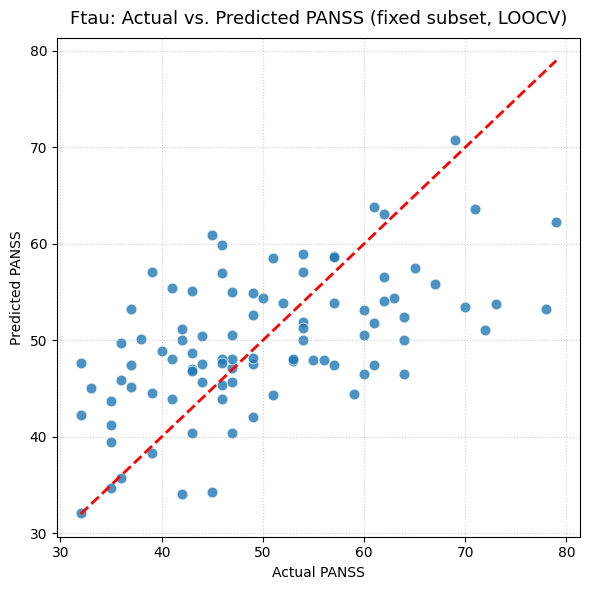

In [7]:
fixed_ftau = report_fixed_feature_model("Ftau", threshold=0.2)

## GEC-only model

/tmp/ipykernel_133140/604961204.py:9: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corrs = np.array([pearsonr(X[:, j], y)[0] for j in range(X.shape[1])])



=== GEC: fixed matrix-element subset + Ridge (threshold=0.2) ===
Selected 133 / 9900 matrix elements (fixed across all subjects)
LOOCV R2   = 0.2232
LOOCV RMSE = 9.8559
LOOCV MAE  = 7.9830
Corr(y, yhat) = 0.4730  (p=0.0000)
Final model (fit on all subjects) alpha = 0.03162


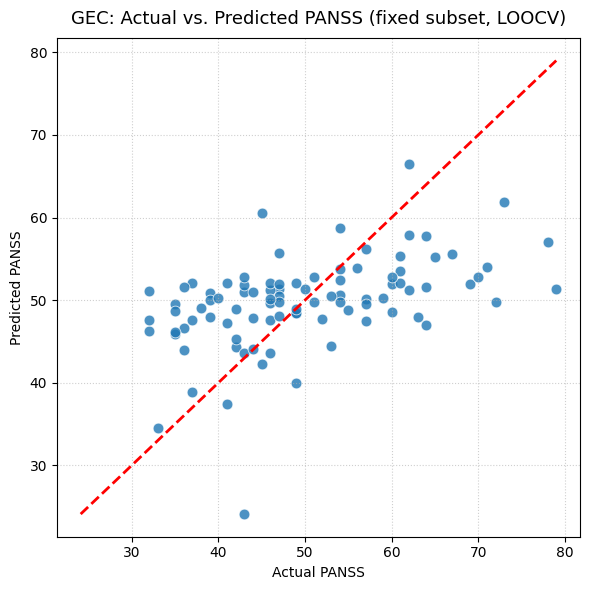

In [8]:
fixed_gec = report_fixed_feature_model("GEC", threshold=0.2)

## Does adding perturbability (p2h, p2o) help?

Same fixed-selection + Ridge LOOCV pipeline as above (`threshold=0.2`), but each subject's per-region `p2h` and `p2o` perturbability scores are appended onto the matrix-element features before selection, so they compete for inclusion on equal footing (same correlation threshold, same fixed-subset logic).


=== Ftau+perturbability: fixed subset + Ridge (threshold=0.2) ===
Selected 233 / 10100 features (233 matrix elements, 0 perturbability scores)
LOOCV R2   = 0.3142
LOOCV RMSE = 9.2601
LOOCV MAE  = 7.4926
Corr(y, yhat) = 0.5644  (p=0.0000)


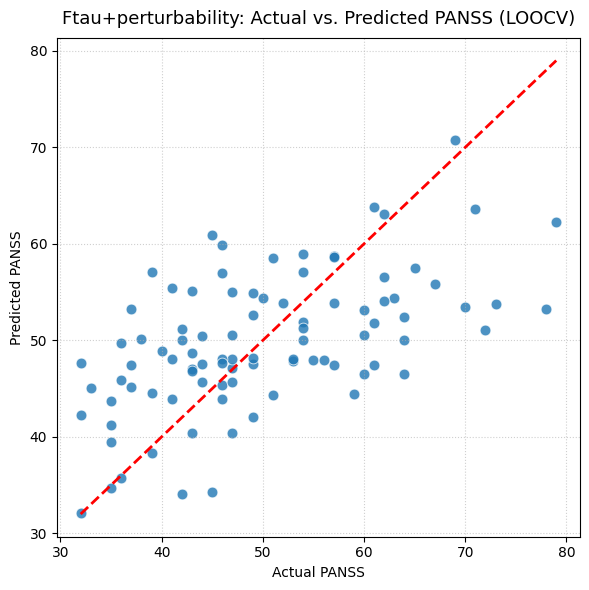

/tmp/ipykernel_133140/604961204.py:9: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corrs = np.array([pearsonr(X[:, j], y)[0] for j in range(X.shape[1])])



=== GEC+perturbability: fixed subset + Ridge (threshold=0.2) ===
Selected 133 / 10100 features (133 matrix elements, 0 perturbability scores)
LOOCV R2   = 0.2232
LOOCV RMSE = 9.8559
LOOCV MAE  = 7.9830
Corr(y, yhat) = 0.4730  (p=0.0000)


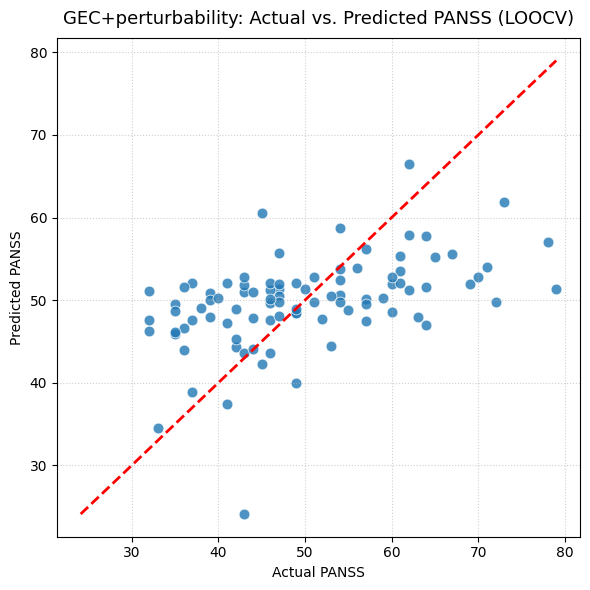

In [9]:
def report_perturbability_model(feature_type, threshold, n_regions=100):
    X, y = build_dataset_elements(feature_type, include_perturbability=True)
    X = X[:, :-1]  # drop the group flag
    n_matrix_feats = int(offdiag_mask(n_regions).sum())

    selected_idx = select_fixed_features(X, y, threshold)
    n_matrix_selected = int(np.sum(selected_idx < n_matrix_feats))
    n_pert_selected = int(np.sum(selected_idx >= n_matrix_feats))

    X_sel = X[:, selected_idx]
    loocv = run_ridge_loocv(X_sel, y)

    print(f"\n=== {feature_type}+perturbability: fixed subset + Ridge (threshold={threshold}) ===")
    print(f"Selected {len(selected_idx)} / {X.shape[1]} features "
          f"({n_matrix_selected} matrix elements, {n_pert_selected} perturbability scores)")
    print(f"LOOCV R2   = {loocv['r2']:.4f}")
    print(f"LOOCV RMSE = {loocv['rmse']:.4f}")
    print(f"LOOCV MAE  = {loocv['mae']:.4f}")
    print(f"Corr(y, yhat) = {loocv['corr']:.4f}  (p={loocv['pval']:.4f})")

    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=loocv["y_true"], y=loocv["y_pred"], color='#1f77b4', s=60, alpha=0.8)
    min_val = min(loocv["y_true"].min(), loocv["y_pred"].min())
    max_val = max(loocv["y_true"].max(), loocv["y_pred"].max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
    plt.title(f'{feature_type}+perturbability: Actual vs. Predicted PANSS (LOOCV)', fontsize=13, pad=10)
    plt.xlabel('Actual PANSS')
    plt.ylabel('Predicted PANSS')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

    return {
        "loocv": loocv,
        "selected_idx": selected_idx,
        "n_matrix_selected": n_matrix_selected,
        "n_pert_selected": n_pert_selected,
    }


perturbability_ftau = report_perturbability_model("Ftau", threshold=0.2)
perturbability_gec = report_perturbability_model("GEC", threshold=0.2)

In [10]:
comparison = pd.DataFrame([
    {"model": "Ftau", **{k: fixed_ftau["loocv"][k] for k in ("r2", "corr", "pval")},
     "n_features": len(fixed_ftau["selected_idx"])},
    {"model": "Ftau + perturbability", **{k: perturbability_ftau["loocv"][k] for k in ("r2", "corr", "pval")},
     "n_features": len(perturbability_ftau["selected_idx"])},
    {"model": "GEC", **{k: fixed_gec["loocv"][k] for k in ("r2", "corr", "pval")},
     "n_features": len(fixed_gec["selected_idx"])},
    {"model": "GEC + perturbability", **{k: perturbability_gec["loocv"][k] for k in ("r2", "corr", "pval")},
     "n_features": len(perturbability_gec["selected_idx"])},
])[["model", "n_features", "r2", "corr", "pval"]]
comparison

,model,n_features,r2,corr,pval
0,Ftau,233,0.314246,0.564417,4.639614e-09
1,Ftau + perturbability,233,0.314246,0.564417,4.639614e-09
2,GEC,133,0.223158,0.473034,1.920521e-06
3,GEC + perturbability,133,0.223158,0.473034,1.920521e-06


## Ridge vs. XGBoost on the same fixed subset

Isolates the regressor choice: reuses the exact same fixed feature subset (`selected_idx`) already chosen for `fixed_ftau` / `fixed_gec` at `threshold=0.2`, and only swaps the LOOCV regressor from `RidgeCV` to `XGBRegressor` (same hyperparameters as the original overfitting XGBoost model in this notebook's earlier version, for continuity).


=== Ftau: same fixed subset (233 features), XGBoost LOOCV ===
LOOCV R2   = 0.2075
LOOCV RMSE = 9.9549
LOOCV MAE  = 8.2167
Corr(y, yhat) = 0.4557  (p=0.0000)


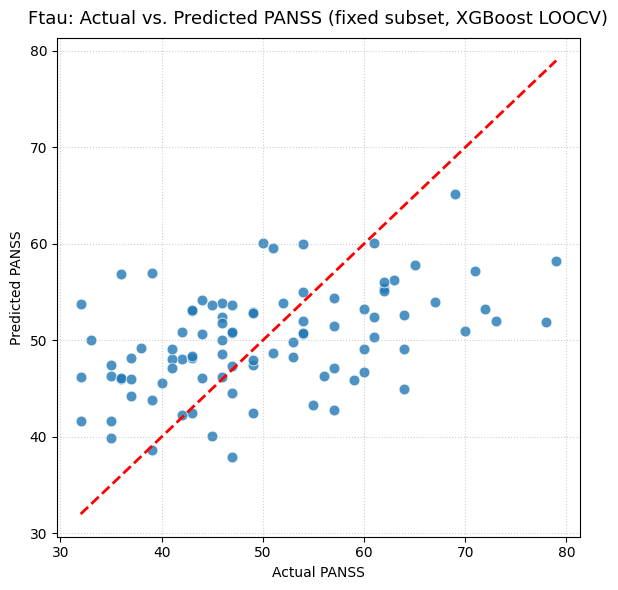


=== GEC: same fixed subset (133 features), XGBoost LOOCV ===
LOOCV R2   = 0.2433
LOOCV RMSE = 9.7274
LOOCV MAE  = 7.6731
Corr(y, yhat) = 0.4936  (p=0.0000)


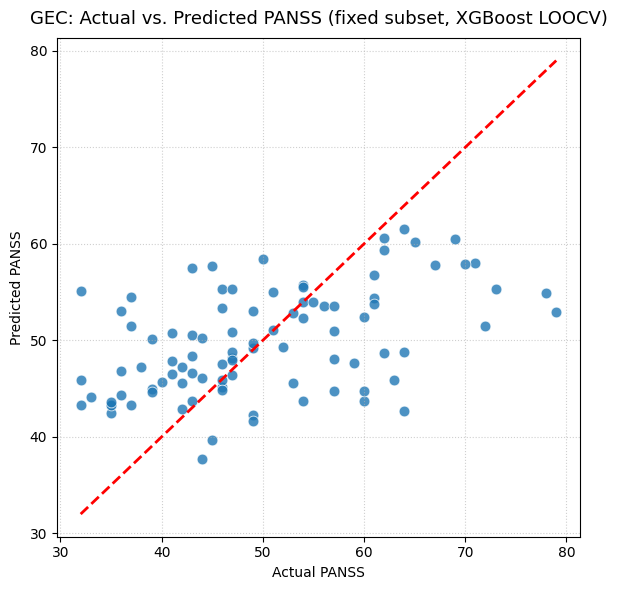

In [11]:
XGB_PARAMS = dict(
    n_estimators=180,
    max_depth=3,
    learning_rate=0.04,
    subsample=0.8,
    colsample_bytree=0.3,
    reg_alpha=0.8,
    reg_lambda=1.5,
    random_state=42,
)


def run_xgb_loocv(X, y, xgb_params):
    """
    XGBRegressor evaluated by LOOCV: refit per fold on the training
    subjects, predict the held-out subject. X's columns are assumed
    already fixed by select_fixed_features.
    """
    loo = LeaveOneOut()
    y_true_all, y_pred_all = [], []

    for train_index, test_index in loo.split(X):
        model = xgb.XGBRegressor(**xgb_params)
        model.fit(X[train_index], y[train_index])
        pred = model.predict(X[test_index])

        y_true_all.append(y[test_index][0])
        y_pred_all.append(pred[0])

    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)
    corr, pval = pearsonr(y_true_all, y_pred_all)

    return {
        "y_true": y_true_all,
        "y_pred": y_pred_all,
        "rmse": np.sqrt(mean_squared_error(y_true_all, y_pred_all)),
        "mae": mean_absolute_error(y_true_all, y_pred_all),
        "r2": r2_score(y_true_all, y_pred_all),
        "corr": corr,
        "pval": pval,
    }


def report_xgb_on_fixed_subset(feature_type, fixed_result):
    X, y = build_dataset_elements(feature_type)
    X_sel = X[:, :-1][:, fixed_result["selected_idx"]]  # drop group flag, same fixed columns as Ridge

    loocv = run_xgb_loocv(X_sel, y, XGB_PARAMS)

    print(f"\n=== {feature_type}: same fixed subset ({X_sel.shape[1]} features), XGBoost LOOCV ===")
    print(f"LOOCV R2   = {loocv['r2']:.4f}")
    print(f"LOOCV RMSE = {loocv['rmse']:.4f}")
    print(f"LOOCV MAE  = {loocv['mae']:.4f}")
    print(f"Corr(y, yhat) = {loocv['corr']:.4f}  (p={loocv['pval']:.4f})")

    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=loocv["y_true"], y=loocv["y_pred"], color='#1f77b4', s=60, alpha=0.8)
    min_val = min(loocv["y_true"].min(), loocv["y_pred"].min())
    max_val = max(loocv["y_true"].max(), loocv["y_pred"].max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
    plt.title(f'{feature_type}: Actual vs. Predicted PANSS (fixed subset, XGBoost LOOCV)', fontsize=13, pad=10)
    plt.xlabel('Actual PANSS')
    plt.ylabel('Predicted PANSS')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

    return loocv


xgb_ftau = report_xgb_on_fixed_subset("Ftau", fixed_ftau)
xgb_gec = report_xgb_on_fixed_subset("GEC", fixed_gec)

In [12]:
regressor_comparison = pd.DataFrame([
    {"model": "Ftau (Ridge)", "n_features": len(fixed_ftau["selected_idx"]),
     **{k: fixed_ftau["loocv"][k] for k in ("r2", "corr", "pval")}},
    {"model": "Ftau (XGBoost)", "n_features": len(fixed_ftau["selected_idx"]),
     **{k: xgb_ftau[k] for k in ("r2", "corr", "pval")}},
    {"model": "GEC (Ridge)", "n_features": len(fixed_gec["selected_idx"]),
     **{k: fixed_gec["loocv"][k] for k in ("r2", "corr", "pval")}},
    {"model": "GEC (XGBoost)", "n_features": len(fixed_gec["selected_idx"]),
     **{k: xgb_gec[k] for k in ("r2", "corr", "pval")}},
])[["model", "n_features", "r2", "corr", "pval"]]
regressor_comparison

,model,n_features,r2,corr,pval
0,Ftau (Ridge),233,0.314246,0.564417,4.639614e-09
1,Ftau (XGBoost),233,0.207474,0.455665,5.014623e-06
2,GEC (Ridge),133,0.223158,0.473034,1.920521e-06
3,GEC (XGBoost),133,0.243278,0.493619,5.739584e-07


## Threshold sensitivity: LOOCV correlation and feature count vs. threshold

Sweeps the correlation threshold, re-running the full fixed-selection + Ridge LOOCV pipeline at each value, to see how sensitive the result is to that one knob and how many matrix elements survive at each setting.

In [13]:
def threshold_sweep(feature_type, thresholds):
    """
    For each threshold: fix the feature subset on the full sample, run
    Ridge LOOCV, and record how many features were selected alongside the
    resulting LOOCV correlation/R2.
    """
    X, y = build_dataset_elements(feature_type)
    X = X[:, :-1]  # drop the group flag

    records = []
    for threshold in thresholds:
        selected_idx = select_fixed_features(X, y, threshold)
        loocv = run_ridge_loocv(X[:, selected_idx], y)
        records.append({
            "threshold": threshold,
            "n_features": len(selected_idx),
            "corr": loocv["corr"],
            "pval": loocv["pval"],
            "r2": loocv["r2"],
        })
        print(f"[{feature_type}] threshold={threshold:.3f}  n_features={len(selected_idx):4d}  "
              f"corr={loocv['corr']:.4f}  R2={loocv['r2']:.4f}")

    return pd.DataFrame(records)


thresholds = np.arange(0.05, 0.36, 0.025)
sweep_ftau = threshold_sweep("Ftau", thresholds)
sweep_gec = threshold_sweep("GEC", thresholds)

[Ftau] threshold=0.050  n_features=6229  corr=0.1999  R2=0.0307


[Ftau] threshold=0.075  n_features=4601  corr=0.3393  R2=0.1111


[Ftau] threshold=0.100  n_features=3119  corr=0.3611  R2=0.1094


[Ftau] threshold=0.125  n_features=1875  corr=0.4345  R2=0.1741


[Ftau] threshold=0.150  n_features=1037  corr=0.5014  R2=0.2416


...

[GEC] threshold=0.300  n_features=   2  corr=0.2896  R2=0.0834


/tmp/ipykernel_133140/604961204.py:9: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corrs = np.array([pearsonr(X[:, j], y)[0] for j in range(X.shape[1])])


[GEC] threshold=0.325  n_features=   2  corr=0.2896  R2=0.0834


/tmp/ipykernel_133140/604961204.py:9: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corrs = np.array([pearsonr(X[:, j], y)[0] for j in range(X.shape[1])])


[GEC] threshold=0.350  n_features=   1  corr=0.2858  R2=0.0772


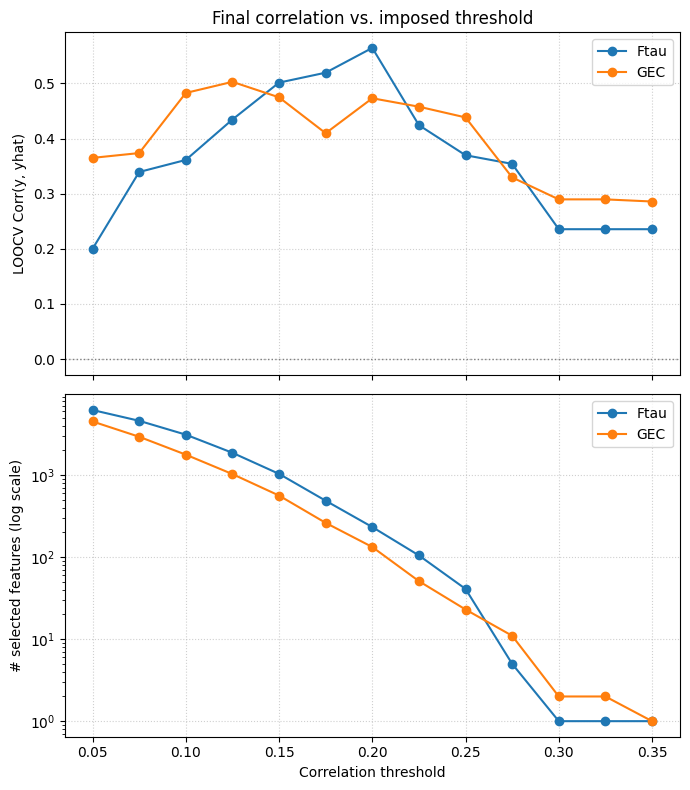

In [14]:
fig, (ax_corr, ax_nfeat) = plt.subplots(2, 1, figsize=(7, 8), sharex=True)

ax_corr.plot(sweep_ftau["threshold"], sweep_ftau["corr"], marker='o', label='Ftau')
ax_corr.plot(sweep_gec["threshold"], sweep_gec["corr"], marker='o', label='GEC')
ax_corr.axhline(0, color='gray', linewidth=1, linestyle=':')
ax_corr.set_ylabel('LOOCV Corr(y, yhat)')
ax_corr.set_title('Final correlation vs. imposed threshold')
ax_corr.legend()
ax_corr.grid(True, linestyle=':', alpha=0.6)

ax_nfeat.plot(sweep_ftau["threshold"], sweep_ftau["n_features"], marker='o', label='Ftau')
ax_nfeat.plot(sweep_gec["threshold"], sweep_gec["n_features"], marker='o', label='GEC')
ax_nfeat.set_yscale('log')
ax_nfeat.set_xlabel('Correlation threshold')
ax_nfeat.set_ylabel('# selected features (log scale)')
ax_nfeat.legend()
ax_nfeat.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Notes

- `fixed_ftau` / `fixed_gec` each hold: `loocv` (predictions + R2/RMSE/MAE/corr/p), `selected_idx` (column indices into the flattened off-diagonal matrix), `selected_pairs` (the same indices as `(row_region, col_region)` tuples — this is "which regions to look at"), and `final_model` (a `RidgeCV` fit on every subject, ready to score a new one).
- To predict PANSS for a brand-new subject with no score yet:
  ```python
  new_feats = flatten_offdiag_features(new_subject_matrix)[fixed_ftau["selected_idx"]]
  predicted_panss = fixed_ftau["final_model"].predict(new_feats.reshape(1, -1))
  ```
- `threshold=0.2` selects a few hundred matrix elements out of 9900 for each feature type — checked against the full-sample |corr| distribution first (the single strongest element only reaches ~0.30 for Ftau / ~0.35 for GEC, so much higher than 0.2 collapses toward the single-feature fallback in `select_fixed_features`).
- Because selection uses the full sample, the LOOCV metrics above are optimistic/leaky by design — they measure how well Ridge fits the fixed subset, not a clean estimate of generalization to a truly new subject.